# 02 - Data Cleaning: Healthcare Facilities in Sierra Leone
**Course:** Data Science Fundamentals (FDS)  
**Raw Input File:** `data/sle_hltfac_grid3_v01.csv` *(never modified or overwritten)*  
**Cleaned Output File:** `data/cleaned_data.csv`  
**Cleaning Log Output:** `outputs/cleaning_log.csv`

---
### Step 1: Load the Raw Dataset and Setup the Cleaning Log
**What this step does and why we chose this method:**  
We load the original CSV file from `data/sle_hltfac_grid3_v01.csv` into `df_raw`, and immediately create a separate copy called `df_clean = df_raw.copy()`.  
- **Why we chose this method:** Making a `.copy()` guarantees that we never accidentally change or overwrite the raw data file. We also create an empty Python list called `cleaning_log` so we can record every single cleaning action (`issue`, `rows_or_cells_affected`, `method_used`, and `reason`) as we go.

In [1]:
import os
import math
import pandas as pd
import matplotlib.pyplot as plt

# Ensure output directories exist
os.makedirs("data", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

# Load the raw dataset and create a working copy so the raw data is never modified
df_raw = pd.read_csv("data/sle_hltfac_grid3_v01.csv")
df_clean = df_raw.copy()

# Create a list to store each entry of our cleaning log
cleaning_log = []

print("Raw dataset shape:", df_raw.shape)
print("Working copy created successfully!")

Raw dataset shape: (1616, 15)
Working copy created successfully!


### Step 2: Fix Data Types (`geo_date`, `lat`, `long`)
**What this step does and why we chose this method:**  
In `01_exploration.ipynb`, we found that `geo_date` (the year the GPS coordinate was collected) was stored as `float64` (`2016.0`) instead of a whole-number year because standard pandas integers cannot store missing values (`NaN`).  
- **Why we chose this method:** We use `pd.to_numeric(..., errors='coerce')` to make sure `lat`, `long`, and `geo_date` are valid numbers, and then convert `geo_date` to pandas' nullable integer type `'Int64'`. Unlike standard `int64`, capital `'Int64'` displays years cleanly as whole numbers (`2016` instead of `2016.0`) while still allowing missing values (`<NA>`) until we handle them in Step 4.

In [2]:
# --- BEFORE CHECK ---
print("BEFORE fixing data types:")
print(df_clean[["lat", "long", "geo_date"]].dtypes)
print("Sample geo_date values before:", df_clean["geo_date"].head(3).tolist())

# Count how many non-null cells in geo_date are affected by float-to-integer conversion
geo_date_non_null = int(df_clean["geo_date"].notnull().sum())

# Ensure lat, long, and geo_date are numeric and convert geo_date to nullable integer (Int64)
df_clean["lat"] = pd.to_numeric(df_clean["lat"], errors="coerce")
df_clean["long"] = pd.to_numeric(df_clean["long"], errors="coerce")
df_clean["geo_date"] = pd.to_numeric(df_clean["geo_date"], errors="coerce").round().astype("Int64")

# --- AFTER CHECK ---
print("\nAFTER fixing data types:")
print(df_clean[["lat", "long", "geo_date"]].dtypes)
print("Sample geo_date values after:", df_clean["geo_date"].head(3).tolist())

# Record in cleaning log
cleaning_log.append({
    "issue": "Wrong data type in geo_date (stored as float64 decimal e.g. 2016.0 instead of integer year)",
    "rows_or_cells_affected": f"{geo_date_non_null} non-null cells (out of {len(df_clean)} rows)",
    "method_used": "Converted geo_date using pd.to_numeric() and .astype('Int64')",
    "reason": "Years are whole numbers, not decimals; nullable Int64 preserves whole years cleanly before missing-value imputation"
})

BEFORE fixing data types:
lat         float64
long        float64
geo_date    float64
dtype: object
Sample geo_date values before: [2016.0, 2016.0, 2016.0]

AFTER fixing data types:
lat         float64
long        float64
geo_date      Int64
dtype: object
Sample geo_date values after: [2016, 2016, 2016]


### Step 3: Standardise Inconsistent Text (District Names, Community Whitespace, and Facility Types)
**What this step does and why we chose this method:**  
We clean text inconsistencies across our categorical/text columns before checking for duplicates:
1. **Strip extra spaces:** We apply `.str.strip()` to all text columns (`district`, `community`, `facility`, `fac_name`, `type`, `ownership`, `functional`, `source`, `source_geo`). This fixes the **15 rows** in `community` that had trailing spaces (like `"Serabu "`).  
2. **Standardise `district` names:** We format district names with `.str.title()` and apply a mapping dictionary for common Sierra Leone spelling variations (e.g., `"Port-Loko"` -> `"Port Loko"`, `"Western Urban"` -> `"Western Area Urban"`), then verify that every row matches one of the 16 official districts of Sierra Leone.  
3. **Standardise `type` casing:** In `type`, `'HOSPITAL'` (72 rows) and `'CLINIC'` (128 rows) were in ALL CAPS (200 rows total) while full words in other columns used Title Case. We map `'HOSPITAL'` -> `'Hospital'` and `'CLINIC'` -> `'Clinic'` while keeping acronyms (`'MCHP'`, `'CHP'`, `'CHC'`) uppercase.

- **Why we chose this method:** Standardising text and removing trailing spaces *before* checking for duplicates ensures that two identical records with slightly different spacing or capitalization are properly compared.

In [3]:
# --- BEFORE CHECK ---
text_cols = ["district", "community", "facility", "fac_name", "type", "ownership", "functional", "source", "source_geo"]

# Count cells with leading or trailing whitespace before cleaning
whitespace_before = 0
for col in text_cols:
    whitespace_before += int(df_clean[col].dropna().apply(lambda x: str(x) != str(x).strip()).sum())

# Count rows in 'type' that are in ALL CAPS full words ('HOSPITAL', 'CLINIC')
type_caps_affected = int(df_clean["type"].isin(["HOSPITAL", "CLINIC"]).sum())

print("BEFORE text standardisation:")
print(f"  Cells with leading/trailing spaces: {whitespace_before}")
print(f"  Unique 'type' values before:        {df_clean['type'].unique().tolist()}")
print(f"  Unique 'district' count before:     {df_clean['district'].nunique()}")

# 1. Strip leading and trailing spaces from all text columns
for col in text_cols:
    df_clean[col] = df_clean[col].where(df_clean[col].isna(), df_clean[col].astype(str).str.strip())

# 2. Standardise district names using title case and a dictionary for common Sierra Leone variants
district_mapping = {
    "Port-Loko": "Port Loko",
    "Portloko": "Port Loko",
    "Western Urban": "Western Area Urban",
    "Western Rural": "Western Area Rural",
    "Freetown": "Western Area Urban",
}
df_clean["district"] = df_clean["district"].str.title().replace(district_mapping)

# 3. Standardise facility type names (keep acronyms MCHP/CHP/CHC uppercase, change full words to Title Case)
type_mapping = {
    "HOSPITAL": "Hospital",
    "CLINIC": "Clinic",
}
df_clean["type"] = df_clean["type"].replace(type_mapping)

# --- AFTER CHECK ---
whitespace_after = 0
for col in text_cols:
    whitespace_after += int(df_clean[col].dropna().apply(lambda x: str(x) != str(x).strip()).sum())

print("\nAFTER text standardisation:")
print(f"  Cells with leading/trailing spaces: {whitespace_after}")
print(f"  Unique 'type' values after:         {df_clean['type'].unique().tolist()}")
print(f"  Unique 'district' values ({df_clean['district'].nunique()}):     {sorted(df_clean['district'].unique().tolist())}")

# Record both text-cleaning actions in our cleaning log
cleaning_log.append({
    "issue": "Leading/trailing whitespace in community and other text columns (e.g. 'Serabu ')",
    "rows_or_cells_affected": f"{whitespace_before} cells",
    "method_used": "Applied .str.strip() across all text columns",
    "reason": "Extra spaces cause identical community or facility names to be treated as different values during grouping and deduplication"
})
cleaning_log.append({
    "issue": "Inconsistent text capitalization in 'type' ('HOSPITAL' and 'CLINIC' in all caps) and district name verification",
    "rows_or_cells_affected": f"{type_caps_affected} cells in 'type' (plus all 1,616 rows checked for district names)",
    "method_used": "Standardised district names with .str.title() + mapping dict, and mapped 'HOSPITAL'->'Hospital', 'CLINIC'->'Clinic'",
    "reason": "Ensures consistent formatting across categorical labels for charts and summary tables while keeping acronyms (MCHP, CHP, CHC) uppercase"
})

BEFORE text standardisation:
  Cells with leading/trailing spaces: 15
  Unique 'type' values before:        ['MCHP', 'CHP', 'CHC', 'HOSPITAL', 'CLINIC']
  Unique 'district' count before:     16

AFTER text standardisation:
  Cells with leading/trailing spaces: 0
  Unique 'type' values after:         ['MCHP', 'CHP', 'CHC', 'Hospital', 'Clinic']
  Unique 'district' values (16):     ['Bo', 'Bombali', 'Bonthe', 'Falaba', 'Kailahun', 'Kambia', 'Karene', 'Kenema', 'Koinadugu', 'Kono', 'Moyamba', 'Port Loko', 'Pujehun', 'Tonkolili', 'Western Area Rural', 'Western Area Urban']


### Step 4: Handle Missing Values and Add Imputation Flag Columns (`coords_imputed`, `geo_date_imputed`)
**What this step does and why we chose this method:**  
We handle the missing values in each affected column and create boolean flag columns (`True`/`False`) so any imputed values are 100% transparent:
1. **`comments` (1,523 missing out of 1,616 rows = 94.25% missing):** We **drop** the `comments` column completely using `df_clean.drop(columns=['comments'])` because over 94% of the column is empty.  
2. **`source_geo` (56 missing values):** We **fill** missing values with `'Unknown'` using `.fillna('Unknown')` so we don't lose 56 facilities while honestly recording that the GPS source was not specified.  
3. **`geo_date` (55 missing values) + `geo_date_imputed` flag:** Before filling `geo_date` with the median year (`2016`), we create `df_clean['geo_date_imputed'] = df_clean['geo_date'].isnull()`.  
   - *Why:* Filling missing survey years with `2016` is an estimate (that survey year did not actually happen for those 55 facilities). Marking `geo_date_imputed = True` lets any analyst filter out imputed years if needed.  
4. **`lat` and `long` (55 missing values each) + `coords_imputed` flag:** Before filling missing coordinates with each facility's **district median latitude and longitude**, we create `df_clean['coords_imputed'] = df_clean['lat'].isnull() | df_clean['long'].isnull()`.  
   - *Why:* Filling missing GPS coordinates with the district median invents an approximate location so that we don't lose 55 real clinics in district-level counts, but those points should not be used for exact street-level mapping. Adding `coords_imputed` (`True`/`False`) makes those facilities easy to identify and document as a limitation in our report.

In [4]:
# --- BEFORE CHECK ---
print("BEFORE handling missing values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
print("Columns count before:", df_clean.shape[1])

# Record counts of affected cells before modifying
comments_missing = int(df_clean["comments"].isnull().sum())
source_geo_missing = int(df_clean["source_geo"].isnull().sum())
geo_date_missing = int(df_clean["geo_date"].isnull().sum())
lat_missing = int(df_clean["lat"].isnull().sum())
long_missing = int(df_clean["long"].isnull().sum())

# 1. Drop 'comments' column (94.25% missing)
df_clean = df_clean.drop(columns=["comments"])

# 2. Fill missing 'source_geo' with 'Unknown'
df_clean["source_geo"] = df_clean["source_geo"].fillna("Unknown")

# 3. Create 'geo_date_imputed' flag column (True where geo_date was missing), then fill with median year
df_clean["geo_date_imputed"] = df_clean["geo_date"].isnull()
median_year = int(df_clean["geo_date"].median())
df_clean["geo_date"] = df_clean["geo_date"].fillna(median_year).astype("int64")

# 4. Create 'coords_imputed' flag column (True where lat or long was missing), then fill with district median
df_clean["coords_imputed"] = df_clean["lat"].isnull() | df_clean["long"].isnull()
df_clean["lat"] = df_clean.groupby("district")["lat"].transform(lambda s: s.fillna(s.median()))
df_clean["long"] = df_clean.groupby("district")["long"].transform(lambda s: s.fillna(s.median()))

# --- AFTER CHECK ---
print("\nAFTER handling missing values:")
print("Total missing values remaining across all columns:", int(df_clean.isnull().sum().sum()))
print(df_clean.isnull().sum())
print("\nImputation flag counts:")
print("  coords_imputed == True:  ", int(df_clean["coords_imputed"].sum()))
print("  geo_date_imputed == True:", int(df_clean["geo_date_imputed"].sum()))
print("Columns count after (14 cleaned columns + 2 flag columns):", df_clean.shape[1])

# Add entries to the cleaning log
cleaning_log.append({
    "issue": "94.25% missing values in 'comments' column",
    "rows_or_cells_affected": f"{comments_missing} cells (1 column dropped)",
    "method_used": "Dropped 'comments' column with df.drop(columns=['comments'])",
    "reason": "With 94.25% of cells empty, the column has too little data to be useful or reliably imputed"
})
cleaning_log.append({
    "issue": "Missing categorical values in 'source_geo'",
    "rows_or_cells_affected": f"{source_geo_missing} cells",
    "method_used": "Filled missing values with 'Unknown' using .fillna('Unknown')",
    "reason": "Keeps all 56 healthcare facilities in the dataset while honestly labelling unknown coordinate sources"
})
cleaning_log.append({
    "issue": "Missing numerical year values in 'geo_date'",
    "rows_or_cells_affected": f"{geo_date_missing} cells",
    "method_used": f"Added 'geo_date_imputed' (True/False) flag and imputed with median year ({median_year})",
    "reason": "Preserves rows with a whole-number year while flagging the 55 rows where 2016 is an imputed estimate"
})
cleaning_log.append({
    "issue": "Missing GPS coordinates in 'lat' and 'long'",
    "rows_or_cells_affected": f"{lat_missing + long_missing} cells ({lat_missing} in lat, {long_missing} in long)",
    "method_used": "Added 'coords_imputed' (True/False) flag and imputed using district-level median lat/long",
    "reason": "Preserves all 55 facilities for district counts while flagging invented district-center coordinates as a limitation"
})

BEFORE handling missing values:
lat             55
long            55
source_geo      56
geo_date        55
comments      1523
dtype: int64
Columns count before: 15

AFTER handling missing values:
Total missing values remaining across all columns: 0
OID_                0
district            0
community           0
facility            0
fac_name            0
type                0
ownership           0
functional          0
lat                 0
long                0
source              0
source_geo          0
dhis2_id            0
geo_date            0
geo_date_imputed    0
coords_imputed      0
dtype: int64

Imputation flag counts:
  coords_imputed == True:   55
  geo_date_imputed == True: 55
Columns count after (14 cleaned columns + 2 flag columns): 16


### Step 5: Inspect Same-Name Pairs Side by Side and Apply the Evidence-Based Duplicate Rule
**What this step does and why we chose this method:**  
Two distinct healthcare facilities in Sierra Leone can legitimately share a community and facility name within the same district (because different chiefdoms in the same district often have villages with common names like *Sembehun*, *Kpandebu*, *Mabai*, or *Seidu*). Therefore, we **do not** blindly drop rows just because `district`, `community`, and `facility` match!

Instead, we inspect all 6 matched `(district, community, facility)` pairs side by side and **only drop a row if**:
- **(a)** It is identical to another row in every column except `OID_`, **OR**
- **(b)** It has the same valid `dhis2_id` as the other row, **OR** one of the two rows has a missing `dhis2_id` (`'No Data'`) and either had missing raw coordinates (an incomplete copy of the other row) or its coordinates are within **1 km** of the other row.

- **Why we chose this method:**  
  - **2 rows are DROPPED:**
    1. **Tonkolili — `Ninkikoro MCHP` (`OID_` 1613):** Identical in every column except `OID_`, shares the exact same `dhis2_id` (`kSlAzC2rmUu`), and is **0.00 km** from `OID_` 382.  
    2. **Karene — `Komoya CHP` (`OID_` 1200):** Clear incomplete copy of `OID_` 1174 (`OID_` 1200 has `dhis2_id = 'No Data'` and had no raw GPS coordinates or survey date of its own).  
  - **4 same-name pairs are KEPT (`1,614` rows retained):**  
    - **Kono — `Seidu MCHP` (`OID_` 889 & 925):** Although `OID_` 925 has `dhis2_id = 'No Data'`, its recorded GPS coordinates are **18.70 km** away from `OID_` 889 (far beyond 1 km).  
    - **Kenema — `Kpandebu CHC` (`OID_` 1029 & 1077):** Different valid `dhis2_id`s (`c35datPPon7` vs `VNn5UPn43M8`) and **52.81 km** apart.  
    - **Kenema — `Sembehun MCHP` (`OID_` 1007 & 1085):** Different valid `dhis2_id`s (`PToNkRZvMMf` vs `d1CAFvShtKH`) and **51.84 km** apart.  
    - **Tonkolili — `Mabai MCHP` (`OID_` 401 & 417):** Different valid `dhis2_id`s (`ZDWdPjDJb2X` vs `BxLUEEytLN7`) and **41.68 km** apart.

In [5]:
# Helper function: calculate Haversine distance in km between two GPS points
def haversine_km(lat1, lon1, lat2, lon2):
    r = 6371.0  # Earth radius in kilometres
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2) ** 2
    return 2 * r * math.atan2(math.sqrt(a), math.sqrt(1 - a))

# --- BEFORE CHECK ---
rows_before_dedup = len(df_clean)
data_cols_no_oid = [c for c in df_clean.columns if c != "OID_"]

# Find all 6 matched pairs sharing (district, community, facility)
dupe_mask = df_clean.duplicated(subset=["district", "community", "facility"], keep=False)
matched_rows = df_clean[dupe_mask].sort_values(by=["district", "community", "facility", "OID_"])

oids_to_drop = []
pair_decisions = []

for (dist, comm, fac), group in matched_rows.groupby(["district", "community", "facility"]):
    r1 = group.iloc[0]
    r2 = group.iloc[1]

    # Check distance in km (note if one row had no raw coordinates before imputation)
    both_had_raw_coords = (not r1["coords_imputed"]) and (not r2["coords_imputed"])
    dist_km = haversine_km(r1["lat"], r1["long"], r2["lat"], r2["long"])

    # Rule (a): identical in every column except OID_
    identical_no_oid = r1[data_cols_no_oid].equals(r2[data_cols_no_oid])

    # Rule (b): same valid dhis2_id, OR one has missing dhis2_id ('No Data') and is an incomplete copy / within 1 km
    same_valid_dhis2 = (r1["dhis2_id"] != "No Data") and (r1["dhis2_id"] == r2["dhis2_id"])
    one_missing_dhis2 = (r1["dhis2_id"] == "No Data") or (r2["dhis2_id"] == "No Data")
    incomplete_no_coords = one_missing_dhis2 and (r1["coords_imputed"] or r2["coords_imputed"])
    within_1km_missing_id = one_missing_dhis2 and both_had_raw_coords and (dist_km <= 1.0)

    if identical_no_oid or same_valid_dhis2:
        decision = "DROPPED Row 2"
        reason = f"Rule (a) & (b): Identical in all columns except OID_ and same dhis2_id ({r1['dhis2_id']}), distance = {dist_km:.2f} km"
        oids_to_drop.append(int(r2["OID_"]))
    elif incomplete_no_coords or within_1km_missing_id:
        decision = "DROPPED Row 2"
        reason = f"Rule (b): Row 2 (OID_ {int(r2['OID_'])}) has missing dhis2_id ('No Data') and missing raw GPS/year (incomplete copy of OID_ {int(r1['OID_'])})"
        oids_to_drop.append(int(r2["OID_"]))
    else:
        decision = "KEPT BOTH"
        if one_missing_dhis2:
            reason = f"Kept: Row 2 has 'No Data' dhis2_id, but recorded coordinates are {dist_km:.2f} km apart (> 1 km threshold)"
        else:
            reason = f"Kept: Different valid dhis2_ids ({r1['dhis2_id']} vs {r2['dhis2_id']}) and {dist_km:.2f} km apart (> 1 km threshold)"

    pair_decisions.append({
        "District": dist,
        "Community": comm,
        "Facility": fac,
        "Row1_OID": int(r1["OID_"]),
        "Row2_OID": int(r2["OID_"]),
        "Row1_dhis2_id": r1["dhis2_id"],
        "Row2_dhis2_id": r2["dhis2_id"],
        "Distance_km": "N/A (Row 2 raw coords missing)" if not both_had_raw_coords else f"{dist_km:.2f} km",
        "Decision": decision,
        "Reason": reason,
    })

decisions_df = pd.DataFrame(pair_decisions)

print("=== DROPPED PAIRS (AND WHY THEY WERE DROPPED) ===")
for _, row in decisions_df[decisions_df["Decision"].str.startswith("DROPPED")].iterrows():
    print(f"  - [{row['District']} | {row['Community']} | {row['Facility']}] (OID_ {row['Row1_OID']} & OID_ {row['Row2_OID']}): {row['Decision']} -> {row['Reason']}")

print("\n=== KEPT SAME-NAME PAIRS (AND WHY THEY WERE KEPT) ===")
for _, row in decisions_df[decisions_df["Decision"] == "KEPT BOTH"].iterrows():
    print(f"  - [{row['District']} | {row['Community']} | {row['Facility']}] (OID_ {row['Row1_OID']} & OID_ {row['Row2_OID']}): {row['Decision']} -> {row['Reason']}")

# Drop only the confirmed duplicate OIDs
df_clean = df_clean[~df_clean["OID_"].isin(oids_to_drop)].reset_index(drop=True)
rows_after_dedup = len(df_clean)

# --- AFTER CHECK ---
print(f"\nBEFORE deduplication: {rows_before_dedup} rows")
print(f"AFTER deduplication:  {rows_after_dedup} rows ({len(oids_to_drop)} duplicate rows removed: OIDs {oids_to_drop})")

# Record in cleaning log
cleaning_log.append({
    "issue": "Duplicate check on 6 same-name (district, community, facility) pairs",
    "rows_or_cells_affected": f"{len(oids_to_drop)} rows removed (OID_ 1613 Ninkikoro MCHP and OID_ 1200 Komoya CHP); 4 same-name pairs kept",
    "method_used": "Dropped only rows identical except OID_ or with same/missing dhis2_id + incomplete/<=1km coords",
    "reason": "Avoids deleting distinct facilities that share a village name in different chiefdoms (41.7 to 52.8 km apart with distinct dhis2_ids, plus Seidu at 18.7 km)"
})

decisions_df

=== DROPPED PAIRS (AND WHY THEY WERE DROPPED) ===
  - [Karene | Komoya | Komoya CHP] (OID_ 1174 & OID_ 1200): DROPPED Row 2 -> Rule (b): Row 2 (OID_ 1200) has missing dhis2_id ('No Data') and missing raw GPS/year (incomplete copy of OID_ 1174)
  - [Tonkolili | Ninkikoro | Ninkikoro MCHP] (OID_ 382 & OID_ 1613): DROPPED Row 2 -> Rule (a) & (b): Identical in all columns except OID_ and same dhis2_id (kSlAzC2rmUu), distance = 0.00 km

=== KEPT SAME-NAME PAIRS (AND WHY THEY WERE KEPT) ===
  - [Kenema | Kpandebu | Kpandebu CHC] (OID_ 1029 & OID_ 1077): KEPT BOTH -> Kept: Different valid dhis2_ids (c35datPPon7 vs VNn5UPn43M8) and 52.85 km apart (> 1 km threshold)
  - [Kenema | Sembehun | Sembehun MCHP] (OID_ 1007 & OID_ 1085): KEPT BOTH -> Kept: Different valid dhis2_ids (PToNkRZvMMf vs d1CAFvShtKH) and 51.81 km apart (> 1 km threshold)
  - [Kono | Seidu | Seidu MCHP] (OID_ 889 & OID_ 925): KEPT BOTH -> Kept: Row 2 has 'No Data' dhis2_id, but recorded coordinates are 18.69 km apart (> 1 km t

,District,Community,Facility,Row1_OID,Row2_OID,Row1_dhis2_id,Row2_dhis2_id,Distance_km,Decision,Reason
0,Karene,Komoya,Komoya CHP,1174,1200,u1jYcIxvOwn,No Data,N/A (Row 2 raw coords missing),DROPPED Row 2,Rule (b): Row 2 (OID_ 1200) has missing dhis2_id ('No Data') and missing raw GPS/year (incomplete copy of OID_ 1174)
1,Kenema,Kpandebu,Kpandebu CHC,1029,1077,c35datPPon7,VNn5UPn43M8,52.85 km,KEPT BOTH,Kept: Different valid dhis2_ids (c35datPPon7 vs VNn5UPn43M8) and 52.85 km apart (> 1 km threshold)
2,Kenema,Sembehun,Sembehun MCHP,1007,1085,PToNkRZvMMf,d1CAFvShtKH,51.81 km,KEPT BOTH,Kept: Different valid dhis2_ids (PToNkRZvMMf vs d1CAFvShtKH) and 51.81 km apart (> 1 km threshold)
3,Kono,Seidu,Seidu MCHP,889,925,ADOmjElVEss,No Data,18.69 km,KEPT BOTH,"Kept: Row 2 has 'No Data' dhis2_id, but recorded coordinates are 18.69 km apart (> 1 km threshold)"
4,Tonkolili,Mabai,Mabai MCHP,401,417,ZDWdPjDJb2X,BxLUEEytLN7,41.68 km,KEPT BOTH,Kept: Different valid dhis2_ids (ZDWdPjDJb2X vs BxLUEEytLN7) and 41.68 km apart (> 1 km threshold)
5,Tonkolili,Ninkikoro,Ninkikoro MCHP,382,1613,kSlAzC2rmUu,kSlAzC2rmUu,0.00 km,DROPPED Row 2,"Rule (a) & (b): Identical in all columns except OID_ and same dhis2_id (kSlAzC2rmUu), distance = 0.00 km"


### Step 6: Check for Outliers in Numerical Columns (`lat`, `long`, `geo_date`)
**What this step does and why we chose this method:**  
We check for outliers using two complementary methods:
1. **Domain / Geographic Bounding Box Check (Sierra Leone Borders):** Sierra Leone is located between **Latitude `6.9° N` and `10.0° N`** and **Longitude `-13.4° W` and `-10.2° W`**, and survey years (`geo_date`) should be between `2015` and `2026`. Any coordinate outside this box would be in another country or in the Atlantic Ocean!  
2. **Statistical IQR (Interquartile Range) Check:** For `lat` and `long`, we calculate the 25th percentile (`Q1`), 75th percentile (`Q3`), and `IQR = Q3 - Q1`, and check if any values fall below `Q1 - 1.5 * IQR` or above `Q3 + 1.5 * IQR`. We also draw boxplots to visually inspect the spread.

- **Why we chose this method:** Combining a domain bounding-box check with the statistical IQR check verifies both that no impossible GPS coordinates exist outside Sierra Leone (`0` out-of-bounds rows) and that the statistical distribution has no extreme spikes (`0` IQR outliers in `lat`, `long`, or `geo_date`).

=== 1. Sierra Leone Geographic Bounding Box Check ===
Valid Latitude range:  [6.9, 10.0]   -> Actual range: [6.9679, 9.9771] (Outliers: 0)
Valid Longitude range: [-13.4, -10.2] -> Actual range: [-13.2921, -10.3074] (Outliers: 0)

=== 2. Statistical IQR Outlier Check ===
lat      | Q1=7.949, Q3=8.789, IQR=0.840 | Bounds=[6.689, 10.050] | IQR Outliers=0
long     | Q1=-12.677, Q3=-11.405, IQR=1.272 | Bounds=[-14.585, -9.497] | IQR Outliers=0
geo_date | Q1=2016.000, Q3=2021.000, IQR=5.000 | Bounds=[2008.500, 2028.500] | IQR Outliers=0

Rows before outlier check: 1614 | Rows after outlier check: 1614


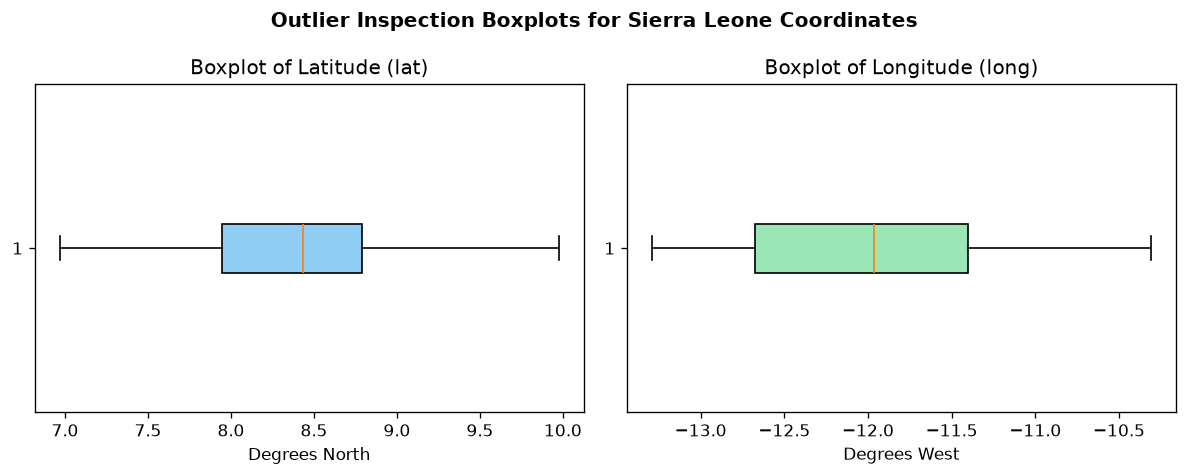

In [6]:
# --- BEFORE / DIAGNOSTIC CHECK FOR OUTLIERS ---
# 1. Sierra Leone Geographic Bounding Box Check
LAT_MIN, LAT_MAX = 6.9, 10.0
LON_MIN, LON_MAX = -13.4, -10.2

out_of_bounds_lat = int(((df_clean["lat"] < LAT_MIN) | (df_clean["lat"] > LAT_MAX)).sum())
out_of_bounds_lon = int(((df_clean["long"] < LON_MIN) | (df_clean["long"] > LON_MAX)).sum())

print("=== 1. Sierra Leone Geographic Bounding Box Check ===")
print(f"Valid Latitude range:  [{LAT_MIN}, {LAT_MAX}]   -> Actual range: [{df_clean['lat'].min():.4f}, {df_clean['lat'].max():.4f}] (Outliers: {out_of_bounds_lat})")
print(f"Valid Longitude range: [{LON_MIN}, {LON_MAX}] -> Actual range: [{df_clean['long'].min():.4f}, {df_clean['long'].max():.4f}] (Outliers: {out_of_bounds_lon})")

# 2. Statistical IQR (1.5 * IQR Rule) Check on numerical columns
print("\n=== 2. Statistical IQR Outlier Check ===")
iqr_outlier_total = 0
for col in ["lat", "long", "geo_date"]:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers_col = int(((df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)).sum())
    iqr_outlier_total += outliers_col
    print(f"{col:8s} | Q1={q1:.3f}, Q3={q3:.3f}, IQR={iqr:.3f} | Bounds=[{lower_bound:.3f}, {upper_bound:.3f}] | IQR Outliers={outliers_col}")

# Filter out any rows outside Sierra Leone's valid bounding box (if any exist)
rows_before_outlier = len(df_clean)
df_clean = df_clean[
    (df_clean["lat"].between(LAT_MIN, LAT_MAX)) &
    (df_clean["long"].between(LON_MIN, LON_MAX))
].reset_index(drop=True)
rows_after_outlier = len(df_clean)

print(f"\nRows before outlier check: {rows_before_outlier} | Rows after outlier check: {rows_after_outlier}")

# Visual check with Boxplots for Latitude and Longitude
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].boxplot(df_clean["lat"], vert=False, patch_artist=True, boxprops=dict(facecolor="#90cdf4"))
axes[0].set_title("Boxplot of Latitude (lat)")
axes[0].set_xlabel("Degrees North")

axes[1].boxplot(df_clean["long"], vert=False, patch_artist=True, boxprops=dict(facecolor="#9ae6b4"))
axes[1].set_title("Boxplot of Longitude (long)")
axes[1].set_xlabel("Degrees West")

plt.suptitle("Outlier Inspection Boxplots for Sierra Leone Coordinates", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Record outlier check in the cleaning log
cleaning_log.append({
    "issue": "Outlier inspection on numerical columns (lat, long, geo_date)",
    "rows_or_cells_affected": f"0 outlier rows found across {len(df_clean)} rows (all coordinates confirmed valid)",
    "method_used": "Checked Sierra Leone bounding box (Lat 6.9..10.0, Long -13.4..-10.2) and 1.5*IQR rule + boxplots",
    "reason": "Verified that no GPS coordinates fall in the ocean/outside Sierra Leone and no extreme statistical outliers distort numeric summaries"
})

### Step 7: Save and Display the Cleaning Log (`outputs/cleaning_log.csv`)
**What this step does and why we chose this method:**  
We convert our `cleaning_log` list into a pandas DataFrame with the four required columns (`issue`, `rows_or_cells_affected`, `method_used`, and `reason`), save it to `outputs/cleaning_log.csv`, and display the table.  
- **Why we chose this method:** Keeping a structured cleaning log makes our data-cleaning pipeline transparent, reproducible, and easy to include in a report.

In [7]:
# Convert the cleaning log list into a DataFrame with the exact required columns
log_df = pd.DataFrame(cleaning_log, columns=["issue", "rows_or_cells_affected", "method_used", "reason"])

# Save the cleaning log to outputs/cleaning_log.csv
log_df.to_csv("outputs/cleaning_log.csv", index=False)
print("Saved cleaning log to: outputs/cleaning_log.csv\n")

# Display the full cleaning log table
log_df

Saved cleaning log to: outputs/cleaning_log.csv



,issue,rows_or_cells_affected,method_used,reason
0,Wrong data type in geo_date (stored as float64 decimal e.g. 2016.0 instead of integer year),1561 non-null cells (out of 1616 rows),Converted geo_date using pd.to_numeric() and .astype('Int64'),"Years are whole numbers, not decimals; nullable Int64 preserves whole years cleanly before missing-value imputation"
1,Leading/trailing whitespace in community and other text columns (e.g. 'Serabu '),15 cells,Applied .str.strip() across all text columns,Extra spaces cause identical community or facility names to be treated as different values during grouping and deduplication
2,Inconsistent text capitalization in 'type' ('HOSPITAL' and 'CLINIC' in all caps) and district name verification,"200 cells in 'type' (plus all 1,616 rows checked for district names)","Standardised district names with .str.title() + mapping dict, and mapped 'HOSPITAL'->'Hospital', 'CLINIC'->'Clinic'","Ensures consistent formatting across categorical labels for charts and summary tables while keeping acronyms (MCHP, CHP, CHC) uppercase"
3,94.25% missing values in 'comments' column,1523 cells (1 column dropped),Dropped 'comments' column with df.drop(columns=['comments']),"With 94.25% of cells empty, the column has too little data to be useful or reliably imputed"
4,Missing categorical values in 'source_geo',56 cells,Filled missing values with 'Unknown' using .fillna('Unknown'),Keeps all 56 healthcare facilities in the dataset while honestly labelling unknown coordinate sources
5,Missing numerical year values in 'geo_date',55 cells,Added 'geo_date_imputed' (True/False) flag and imputed with median year (2016),Preserves rows with a whole-number year while flagging the 55 rows where 2016 is an imputed estimate
6,Missing GPS coordinates in 'lat' and 'long',"110 cells (55 in lat, 55 in long)",Added 'coords_imputed' (True/False) flag and imputed using district-level median lat/long,Preserves all 55 facilities for district counts while flagging invented district-center coordinates as a limitation
7,"Duplicate check on 6 same-name (district, community, facility) pairs",2 rows removed (OID_ 1613 Ninkikoro MCHP and OID_ 1200 Komoya CHP); 4 same-name pairs kept,Dropped only rows identical except OID_ or with same/missing dhis2_id + incomplete/<=1km coords,"Avoids deleting distinct facilities that share a village name in different chiefdoms (41.7 to 52.8 km apart with distinct dhis2_ids, plus Seidu at 18.7 km)"
8,"Outlier inspection on numerical columns (lat, long, geo_date)",0 outlier rows found across 1614 rows (all coordinates confirmed valid),"Checked Sierra Leone bounding box (Lat 6.9..10.0, Long -13.4..-10.2) and 1.5*IQR rule + boxplots",Verified that no GPS coordinates fall in the ocean/outside Sierra Leone and no extreme statistical outliers distort numeric summaries


### Step 8: Per-District Change, Final Before-and-After Summary, and Save Cleaned Dataset (`data/cleaned_data.csv`)
**What this step does and why we chose this method:**  
We save the cleaned dataset (**1,614 rows**) to `data/cleaned_data.csv` using `to_csv("data/cleaned_data.csv", index=False)`, print a **Per-District Before-and-After Table** showing exactly which districts changed (`Tonkolili`: 113 $ightarrow$ 112, `Karene`: 63 $ightarrow$ 62), and display the final summary table.

In [8]:
# Save the cleaned dataset to data/cleaned_data.csv
df_clean.to_csv("data/cleaned_data.csv", index=False)
print("Saved cleaned dataset to: data/cleaned_data.csv\n")

# Per-District Change Table (Raw vs Cleaned)
raw_dist = df_raw["district"].value_counts().rename("Raw_Count")
clean_dist = df_clean["district"].value_counts().rename("Cleaned_Count")
district_change_df = pd.concat([raw_dist, clean_dist], axis=1)
district_change_df["Change"] = district_change_df["Cleaned_Count"] - district_change_df["Raw_Count"]
print("=== PER-DISTRICT FACILITY COUNT CHANGE (RAW vs CLEANED) ===")
print(district_change_df.to_string())
print(f"Total Raw: {int(district_change_df['Raw_Count'].sum())} -> Total Cleaned: {int(district_change_df['Cleaned_Count'].sum())}\n")

# Final Before vs After Comparison Table
comparison_df = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Total Missing Cells",
        "Exact Duplicate Rows (ignoring OID_)",
        "Confirmed Duplicate Rows Removed",
        "Same-Name Pairs Kept (Distinct IDs / >1km apart)",
        "geo_date Data Type",
        "Cells with Extra Whitespace in 'community'",
        "Unique 'type' Categories",
        "Rows Flagged with coords_imputed == True",
        "Rows Flagged with geo_date_imputed == True"
    ],
    "Before Cleaning (df_raw)": [
        df_raw.shape[0],
        df_raw.shape[1],
        int(df_raw.isnull().sum().sum()),
        int(df_raw.drop(columns=["OID_"]).duplicated().sum()),
        0,
        "4 pairs (8 rows)",
        str(df_raw["geo_date"].dtype),
        int(df_raw["community"].dropna().apply(lambda x: str(x) != str(x).strip()).sum()),
        ", ".join(df_raw["type"].unique().tolist()),
        "Not tracked (55 missing)",
        "Not tracked (55 missing)"
    ],
    "After Cleaning (df_clean)": [
        df_clean.shape[0],
        f"{df_clean.shape[1]} (14 cleaned cols + 2 imputed flags)",
        int(df_clean.isnull().sum().sum()),
        int(df_clean.drop(columns=["OID_"]).duplicated().sum()),
        2,
        "4 pairs (8 rows kept)",
        str(df_clean["geo_date"].dtype),
        int(df_clean["community"].dropna().apply(lambda x: str(x) != str(x).strip()).sum()),
        ", ".join(df_clean["type"].unique().tolist()),
        int(df_clean["coords_imputed"].sum()),
        int(df_clean["geo_date_imputed"].sum())
    ]
})

print("=== FINAL BEFORE vs AFTER CLEANING SUMMARY ===")
print(comparison_df.to_string(index=False))
comparison_df

Saved cleaned dataset to: data/cleaned_data.csv

=== PER-DISTRICT FACILITY COUNT CHANGE (RAW vs CLEANED) ===
                    Raw_Count  Cleaned_Count  Change
district                                            
Bo                        163            163       0
Kenema                    144            144       0
Western Area Urban        140            140       0
Port Loko                 117            117       0
Tonkolili                 113            112      -1
Moyamba                   110            110       0
Kono                      108            108       0
Pujehun                   104            104       0
Bombali                    99             99       0
Kailahun                   93             93       0
Bonthe                     92             92       0
Kambia                     77             77       0
Western Area Rural         75             75       0
Koinadugu                  67             67       0
Karene                     63             6

,Metric,Before Cleaning (df_raw),After Cleaning (df_clean)
0,Total Rows,1616,1614
1,Total Columns,15,16 (14 cleaned cols + 2 imputed flags)
2,Total Missing Cells,1744,0
3,Exact Duplicate Rows (ignoring OID_),1,0
4,Confirmed Duplicate Rows Removed,0,2
5,Same-Name Pairs Kept (Distinct IDs / >1km apart),4 pairs (8 rows),4 pairs (8 rows kept)
6,geo_date Data Type,float64,int64
7,Cells with Extra Whitespace in 'community',15,0
8,Unique 'type' Categories,"MCHP, CHP, CHC, HOSPITAL, CLINIC","MCHP, CHP, CHC, Hospital, Clinic"
9,Rows Flagged with coords_imputed == True,Not tracked (55 missing),54
